## Sprint 3 — Feature Engineering: OULAD (Open University Learning Analytics Dataset)

Informed by the deep-dive EDA notebook's findings, and
restructured to match `feature_engineering_uci.ipynb`'s pattern (correlation
plots, leakage check, boxplots by risk, risk rate by category, target
distribution). Goal: a richer, more accurate feature matrix, not just a wider
one — every addition below is tied to a specific EDA finding, not added for
its own sake.

`studentInfo.csv` already has `final_result`
(`Distinction`/`Pass`/`Fail`/`Withdrawn`), but the binary target still needs one derivation step:

```
at_risk = 1  if final_result in {"Fail", "Withdrawn"}
at_risk = 0  if final_result in {"Pass", "Distinction"}
```


### What this notebook does, in order
1. Load `studentInfo.csv` and derive `at_risk`
2. Stream `studentVle.csv` into weekly engagement (chunked) — unchanged
3. Aggregate weekly engagement into per-student features, **+ engagement trend**
4. **New:** build the assessment submission-rate feature
5. Join engagement + **expanded demographic** features + target, resolve duplicates
6. Encode categoricals (nominal one-hot, ordinal mapped, leakage columns dropped)
7. Sanity checks
8. Save the feature matrix
9. **New:** correlation with target, leakage check, boxplots by risk, risk rate by category, target distribution — same visual pattern as `feature_engineering_uci.ipynb`

In [1]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", 60)

PROJECT_ROOT = r"C:\Users\KaranSanjayJadhav\Desktop\Karan_Jadhav_student_analytics_streamlit\student_analytics_cli"
RAW_DIR = os.path.join(PROJECT_ROOT, "data", "raw", "oulad_data")
PROCESSED_DIR = os.path.join(PROJECT_ROOT, "data", "processed")
os.makedirs(PROCESSED_DIR, exist_ok=True)

def read_oulad(name, **kwargs):
    return pd.read_csv(os.path.join(RAW_DIR, name), na_values="?", **kwargs)

## 1. Load `studentInfo` and derive `at_risk`

In [2]:
# Load OULAD student information
student_info = read_oulad("studentInfo.csv")


# Display dataset information
print(
    f"studentInfo: "
    f"{student_info.shape[0]:,} rows × "
    f"{student_info.shape[1]} columns"
)


# Check final result distribution
print("\nFinal Result Distribution:")
print(student_info["final_result"].value_counts())


# Create At-Risk target
# Fail and Withdrawn → At Risk (1)
# Pass and Distinction → Safe (0)
student_info["at_risk"] = (
    student_info["final_result"]
    .isin(["Fail", "Withdrawn"])
    .astype(int)
)


# Display At-Risk rate
print(
    f"\nOverall At-Risk Rate: "
    f"{student_info['at_risk'].mean():.1%}"
)

studentInfo: 32,593 rows × 12 columns

Final Result Distribution:
final_result
Pass           12361
Withdrawn      10156
Fail            7052
Distinction     3024
Name: count, dtype: int64

Overall At-Risk Rate: 52.8%


**Why Fail + Withdrawn, not just Fail?** Both represent a student who did not
successfully complete the module — unchanged reasoning from the original
version. 3,808 students appear in more than one module/presentation; resolved
in Section 5 by keeping each student's worst recorded outcome, same as before.

## 2. Stream `studentVle.csv` into weekly engagement (chunked)

Unchanged from the original version — `studentVle.csv` is ~10.65M rows /
~433MB, streamed in 1M-row chunks into a `(student, week)` long-format table.

In [14]:
# 24. OULAD Weekly Engagement Features

vle_path = os.path.join(RAW_DIR, "studentVle.csv")
CHUNK_SIZE = 1_000_000

# Dictionaries to store weekly engagement
weekly_clicks = {}
weekly_days = {}

total_rows = 0


# --------------------------------------------------
# Read studentVle.csv in chunks
# --------------------------------------------------

for chunk in pd.read_csv(
    vle_path,
    na_values="?",
    chunksize=CHUNK_SIZE
):

    total_rows += len(chunk)

    # Convert day number into week number
    # Negative weeks = before course start
    # Week 0 = course start
    # Positive weeks = during course
    chunk["week_number"] = (
        chunk["date"] // 7
    ).astype(int)


    # --------------------------------------------------
    # 1. Calculate total clicks per student-week
    # --------------------------------------------------

    click_data = (
        chunk
        .groupby(
            ["id_student", "week_number"]
        )["sum_click"]
        .sum()
    )

    for (student_id, week), clicks in click_data.items():

        key = (student_id, week)

        weekly_clicks[key] = (
            weekly_clicks.get(key, 0) + clicks
        )


    # --------------------------------------------------
    # 2. Calculate active days per student-week
    # --------------------------------------------------

    day_data = (
        chunk
        .groupby(
            ["id_student", "week_number"]
        )["date"]
        .apply(lambda x: set(x.unique()))
    )

    for (student_id, week), days in day_data.items():

        key = (student_id, week)

        weekly_days.setdefault(
            key,
            set()
        ).update(days)


# --------------------------------------------------
# Create complete weekly engagement table
# --------------------------------------------------

weekly = pd.DataFrame([
    {
        "id_student": student_id,
        "week_number": week,
        "total_clicks": clicks,
        "days_active": len(
            weekly_days[(student_id, week)]
        )
    }
    for (student_id, week), clicks
    in weekly_clicks.items()
])


# Sort the data
weekly = weekly.sort_values(
    ["id_student", "week_number"]
).reset_index(drop=True)


# --------------------------------------------------
# Create course-period table
# --------------------------------------------------

weekly_course = weekly[
    weekly["week_number"] >= 0
].copy()


# --------------------------------------------------
# Display summary
# --------------------------------------------------

print(f"Processed rows: {total_rows:,}")

print(
    f"Complete weekly table: "
    f"{weekly.shape[0]:,} student-week rows"
)

print(
    f"Course-period table: "
    f"{weekly_course.shape[0]:,} student-week rows"
)

print(
    f"\nWeek range in complete data: "
    f"{weekly['week_number'].min()} "
    f"to {weekly['week_number'].max()}"
)

print(
    f"Week range used for modeling/dashboard: "
    f"{weekly_course['week_number'].min()} "
    f"to {weekly_course['week_number'].max()}"
)


# --------------------------------------------------
# Preview
# --------------------------------------------------

print("\nComplete temporal data:")
display(weekly.head(10))


print("\nCourse-period data:")
display(weekly_course.head(10))

Processed rows: 10,655,280
Complete weekly table: 584,911 student-week rows
Course-period table: 541,296 student-week rows

Week range in complete data: -4 to 38
Week range used for modeling/dashboard: 0 to 38

Complete temporal data:


,id_student,week_number,total_clicks,days_active
0,6516,-4,110,2
1,6516,-3,48,2
2,6516,-2,2,1
3,6516,-1,96,4
4,6516,0,229,6
5,6516,1,42,4
6,6516,2,79,5
7,6516,3,193,3
8,6516,4,69,4
9,6516,5,34,5



Course-period data:


,id_student,week_number,total_clicks,days_active
4,6516,0,229,6
5,6516,1,42,4
6,6516,2,79,5
7,6516,3,193,3
8,6516,4,69,4
9,6516,5,34,5
10,6516,6,10,2
11,6516,7,93,7
12,6516,8,57,5
13,6516,9,61,5


In [15]:
# Create Weekly Student Engagement Table

weekly = pd.DataFrame([
    {
        "id_student": student_id,
        "week_number": week,
        "total_clicks": clicks,
        "days_active": len(
            weekly_days[(student_id, week)]
        )
    }
    for (student_id, week), clicks in weekly_clicks.items()
])


# Display table information
print(
    f"Weekly engagement table: "
    f"{weekly.shape[0]:,} rows "
    f"(one row per student-week)"
)


# Preview data
display(weekly.head(25))

Weekly engagement table: 584,911 rows (one row per student-week)


,id_student,week_number,total_clicks,days_active
0,6516,-4,110,2
1,6516,-3,48,2
2,6516,-2,2,1
3,6516,-1,96,4
4,6516,0,229,6
5,6516,1,42,4
6,6516,2,79,5
7,6516,3,193,3
8,6516,4,69,4
9,6516,5,34,5


In [16]:
student_6516 = []

for (sid, wk), days in weekly_days.items():
    if sid == 6516 and wk == 0:
        student_6516 = sorted(days)

print("Student 6516, Week 0 dates:")
print(student_6516)

print("Number of active days:", len(student_6516))

Student 6516, Week 0 dates:
[0, 1, 2, 3, 5, 6]
Number of active days: 6


## 3. Aggregate weekly engagement into per-student features (+ engagement trend)

Same 6 aggregates as the original version (`total_clicks_sum/mean/max`,
`days_active_sum/mean`, `num_weeks_active`), **plus one new feature**:

**`engagement_trend`** — mean weekly clicks in the *second half* of a
student's active weeks minus the *first half*. Positive means engagement grew
over time; negative means it declined. This exists because the deep-dive
EDA's cumulative-trajectory chart showed outcome groups separating by *shape*
over time, not just *total volume* — two students with the same
`total_clicks_sum` can have opposite trends, and the original feature set had
no way to tell them apart.

In [17]:
# 26. Create Per-Student Engagement Features

# --------------------------------------------------
# Calculate engagement trend
# --------------------------------------------------

def compute_trend(group):
    """
    Calculate the change in weekly engagement.

    Trend =
        Mean clicks in second half
        - Mean clicks in first half

    Positive value  -> engagement increased
    Negative value  -> engagement decreased
    Zero            -> no measurable change
    """

    group = group.sort_values("week_number")

    # No trend can be calculated with only one week
    if len(group) < 2:
        return 0.0

    midpoint = len(group) // 2

    first_half = group["total_clicks"].iloc[:midpoint].mean()
    second_half = group["total_clicks"].iloc[midpoint:].mean()

    return float(second_half - first_half)


# Calculate trend for each student
engagement_trend = (
    weekly_course
    .groupby("id_student")
    .apply(
        compute_trend,
        include_groups=False
    )
    .rename("engagement_trend")
)


# --------------------------------------------------
# Aggregate weekly engagement into student-level data
# --------------------------------------------------

agg = (
    weekly_course
    .groupby("id_student")
    .agg(
        total_clicks_sum=("total_clicks", "sum"),
        total_clicks_mean=("total_clicks", "mean"),
        total_clicks_max=("total_clicks", "max"),
        days_active_sum=("days_active", "sum"),
        days_active_mean=("days_active", "mean"),
        num_weeks_active=("week_number", "count")
    )
    .join(engagement_trend)
    .reset_index()
)


# --------------------------------------------------
# Display results
# --------------------------------------------------

print(
    f"Per-student engagement features: "
    f"{agg.shape[0]:,} students × "
    f"{agg.shape[1] - 1} features"
)

display(agg.head())

Per-student engagement features: 25,516 students × 7 features


,id_student,total_clicks_sum,total_clicks_mean,total_clicks_max,days_active_sum,days_active_mean,num_weeks_active,engagement_trend
0,6516,2535,72.428571,229,150,4.285714,35,7.009804
1,8462,575,35.937500,156,51,3.187500,16,-39.625000
2,11391,836,32.153846,183,39,1.500000,26,-15.846154
3,23629,147,14.700000,35,15,1.500000,10,10.600000
4,23698,729,30.375000,140,57,2.375000,24,2.916667


## 4. New: assessment submission-rate feature

**`pct_assessments_submitted`** — share of a student's module assessments they
actually submitted, out of the assessments that existed for their module.
`Exam`-type assessments are excluded from the "expected" set, since exam
submission isn't tracked the same consistent way across module presentations
in this dataset (same exclusion used in the deep-dive EDA's submission funnel).

This directly encodes the EDA's finding that **non-submission is itself risk
signal**, separate from low scores on what *was* submitted — something the
original feature set had no way to capture (it only used engagement clicks,
never touched the assessment tables at all).

In [18]:
# 27. Calculate Assessment Submission Rate

# --------------------------------------------------
# Load assessment datasets
# --------------------------------------------------

assessments = read_oulad("assessments.csv")
student_assessment = read_oulad("studentAssessment.csv")


# --------------------------------------------------
# Get non-exam assessments
# --------------------------------------------------

non_exam_assessments = assessments[
    assessments["assessment_type"] != "Exam"
]


# --------------------------------------------------
# Create module → expected assessment lookup
# --------------------------------------------------

assessments_by_module = (
    non_exam_assessments
    .groupby("code_module")["id_assessment"]
    .apply(set)
    .to_dict()
)


# --------------------------------------------------
# Create student → module lookup
# --------------------------------------------------

student_module_lookup = (
    student_info
    .drop_duplicates("id_student")
    .set_index("id_student")["code_module"]
    .to_dict()
)


# --------------------------------------------------
# Create student → submitted assessments lookup
# --------------------------------------------------

submitted_by_student = (
    student_assessment
    .groupby("id_student")["id_assessment"]
    .apply(set)
    .to_dict()
)


# --------------------------------------------------
# Calculate submission rate for each student
# --------------------------------------------------

submission_rows = []

for student_id, module in student_module_lookup.items():

    expected = assessments_by_module.get(module, set())

    # Skip modules without non-exam assessments
    if not expected:
        continue

    submitted = submitted_by_student.get(
        student_id,
        set()
    )

    submitted_count = len(
        submitted & expected
    )

    submission_rate = (
        submitted_count / len(expected)
    )

    submission_rows.append({
        "id_student": student_id,
        "pct_assessments_submitted": submission_rate
    })


# --------------------------------------------------
# Create final DataFrame
# --------------------------------------------------

submission_df = pd.DataFrame(submission_rows)


# --------------------------------------------------
# Display summary
# --------------------------------------------------

print(
    f"Submission rate calculated for "
    f"{len(submission_df):,} students"
)

print(
    f"Mean assessment submission rate: "
    f"{submission_df['pct_assessments_submitted'].mean():.3f}"
)

display(submission_df.head())

Submission rate calculated for 28,785 students
Mean assessment submission rate: 0.182


,id_student,pct_assessments_submitted
0,11391,0.5
1,28400,0.5
2,30268,0.0
3,31604,0.5
4,32885,0.5


## 5. Join engagement + expanded demographics + target, resolve duplicates

In [19]:
# Combine Engagement, Student Information & Assessment Features

# --------------------------------------------------
# 1. Keep the worst outcome for duplicate students
# --------------------------------------------------

outcome_rank = {
    "Distinction": 0,
    "Pass": 1,
    "Fail": 2,
    "Withdrawn": 3
}

info_dedup = (
    student_info
    .assign(outcome_rank=student_info["final_result"].map(outcome_rank))
    .sort_values("outcome_rank", ascending=False)
    .drop_duplicates("id_student", keep="first")
    .drop(columns="outcome_rank")
)


# --------------------------------------------------
# 2. Select student information features
# --------------------------------------------------

keep_cols = [
    "id_student",
    "code_module",
    "gender",
    "region",
    "highest_education",
    "imd_band",
    "age_band",
    "disability",
    "num_of_prev_attempts",
    "studied_credits",
    "final_result",
    "at_risk"
]

info_slim = info_dedup[keep_cols]


# --------------------------------------------------
# 3. Merge engagement features
# --------------------------------------------------

merged = agg.merge(
    info_slim,
    on="id_student",
    how="inner"
)


# --------------------------------------------------
# 4. Add assessment submission rate
# --------------------------------------------------

merged = merged.merge(
    submission_df,
    on="id_student",
    how="left"
)

# Students without submission records
# are treated as having 0% submission
merged["pct_assessments_submitted"] = (
    merged["pct_assessments_submitted"]
    .fillna(0.0)
)


# --------------------------------------------------
# 5. Check how many students were retained
# --------------------------------------------------

total_students = student_info["id_student"].nunique()
final_students = merged["id_student"].nunique()
dropped_students = total_students - final_students

print(
    f"Unique students in studentInfo: "
    f"{total_students:,}"
)

print(
    f"Students in final feature matrix: "
    f"{final_students:,}"
)

print(
    f"Students dropped: "
    f"{dropped_students:,} "
    f"({dropped_students / total_students:.1%})"
)

print(
    "\nStudents are retained only when they have "
    "both student information and VLE engagement data."
)


# --------------------------------------------------
# 6. Preview final merged data
# --------------------------------------------------

display(merged.head())

Unique students in studentInfo: 28,785
Students in final feature matrix: 25,516
Students dropped: 3,269 (11.4%)

Students are retained only when they have both student information and VLE engagement data.


,id_student,total_clicks_sum,total_clicks_mean,total_clicks_max,days_active_sum,days_active_mean,num_weeks_active,engagement_trend,code_module,gender,region,highest_education,imd_band,age_band,disability,num_of_prev_attempts,studied_credits,final_result,at_risk,pct_assessments_submitted
0,6516,2535,72.428571,229,150,4.285714,35,7.009804,AAA,M,Scotland,HE Qualification,80-90%,55<=,N,0,60,Pass,0,0.500000
1,8462,575,35.937500,156,51,3.187500,16,-39.625000,DDD,M,London Region,HE Qualification,30-40%,55<=,N,1,60,Withdrawn,1,0.225806
2,11391,836,32.153846,183,39,1.500000,26,-15.846154,AAA,M,East Anglian Region,HE Qualification,90-100%,55<=,N,0,240,Pass,0,0.500000
3,23629,147,14.700000,35,15,1.500000,10,10.600000,BBB,F,East Anglian Region,Lower Than A Level,20-30%,0-35,N,2,60,Fail,1,0.105263
4,23698,729,30.375000,140,57,2.375000,24,2.916667,CCC,F,East Anglian Region,A Level or Equivalent,50-60%,0-35,N,0,120,Pass,0,0.500000


Same inner-join limitation the original version had — still worth flagging,
not silently inherited: students with a recorded outcome but zero VLE activity
get dropped here, same as before. `pct_assessments_submitted` uses a `left`
join with `fillna(0.0)` instead, since a student legitimately can have zero
submissions without having zero rows to join against.

## 6. Encode categoricals + drop leakage columns

Three different encoding treatments, chosen per column's actual structure —
matching the UCI notebook's principle of encoding based on what a column
actually represents, not applying one blanket method to everything:

- **Nominal, one-hot** (`code_module`, `region`) — no inherent order between categories.
- **Ordinal, integer-mapped** (`age_band`, `highest_education`, `imd_band`) —
  these have a real order (younger→older, less→more education, less→more
  deprived), so mapping to an ordered integer preserves that instead of
  throwing it away the way one-hot would.
- **Binary, one-hot** (`gender`, `disability`) — `drop_first=True` as usual.

In [20]:
# 29. Encode Ordinal Demographic Features

# --------------------------------------------------
# 1. Define ordinal mappings
# --------------------------------------------------

age_band_map = {
    "0-35": 0,
    "35-55": 1,
    "55<=": 2
}

education_map = {
    "No Formal quals": 0,
    "Lower Than A Level": 1,
    "A Level or Equivalent": 2,
    "HE Qualification": 3,
    "Post Graduate Qualification": 4
}


# --------------------------------------------------
# 2. Convert IMD band to numeric midpoint
# --------------------------------------------------

def imd_band_to_numeric(band):
    """
    Convert an IMD percentage band to its midpoint.

    Example:
        0-10%  -> 5
        10-20  -> 15
        20-30  -> 25
    """

    if pd.isna(band):
        return np.nan

    match = re.match(r"(\d+)-(\d+)", str(band))

    if not match:
        return np.nan

    low, high = map(int, match.groups())

    return (low + high) / 2


# --------------------------------------------------
# 3. Apply ordinal encoding
# --------------------------------------------------

merged["age_band_ordinal"] = (
    merged["age_band"].map(age_band_map)
)

merged["highest_education_ordinal"] = (
    merged["highest_education"].map(education_map)
)


# --------------------------------------------------
# 4. Handle missing IMD values
# --------------------------------------------------

# Keep a separate indicator showing which values were missing
merged["imd_band_missing"] = (
    merged["imd_band"].isna().astype(int)
)


# Convert IMD bands to numeric values
merged["imd_band_ordinal"] = (
    merged["imd_band"]
    .apply(imd_band_to_numeric)
)


# Fill missing IMD values with the median
merged["imd_band_ordinal"] = (
    merged["imd_band_ordinal"]
    .fillna(merged["imd_band_ordinal"].median())
)


# --------------------------------------------------
# 5. Display results
# --------------------------------------------------

print(
    "IMD missing rate:",
    f"{merged['imd_band_missing'].mean():.3f}"
)

display(
    merged[
        [
            "age_band",
            "age_band_ordinal",
            "highest_education",
            "highest_education_ordinal",
            "imd_band",
            "imd_band_ordinal",
            "imd_band_missing"
        ]
    ].head()
)

IMD missing rate: 0.036


,age_band,age_band_ordinal,highest_education,highest_education_ordinal,imd_band,imd_band_ordinal,imd_band_missing
0,55<=,2,HE Qualification,3,80-90%,85.0,0
1,55<=,2,HE Qualification,3,30-40%,35.0,0
2,55<=,2,HE Qualification,3,90-100%,95.0,0
3,0-35,0,Lower Than A Level,1,20-30%,25.0,0
4,0-35,0,A Level or Equivalent,2,50-60%,55.0,0


In [21]:
# 30. Create Final OULAD Feature Matrix

# --------------------------------------------------
# 1. Define categorical columns
# --------------------------------------------------

nominal_cols = [
    "code_module",
    "region"
]

binary_cols = [
    "gender",
    "disability"
]


# --------------------------------------------------
# 2. One-hot encode categorical features
# --------------------------------------------------

categorical_cols = nominal_cols + binary_cols

merged_encoded = pd.get_dummies(
    merged,
    columns=categorical_cols,
    drop_first=True
)


# --------------------------------------------------
# 3. Remove target, identifiers, and raw categorical columns
# --------------------------------------------------

drop_cols = [
    "final_result",       # Target leakage
    "id_student",         # Identifier
    "age_band",           # Ordinal version already created
    "highest_education",  # Ordinal version already created
    "imd_band"            # Numeric version already created
]

df_features = merged_encoded.drop(
    columns=[
        col for col in drop_cols
        if col in merged_encoded.columns
    ]
)


# --------------------------------------------------
# 4. Keep only ML-compatible columns
# --------------------------------------------------

df_features = df_features.select_dtypes(
    include=["number", "bool"]
)


# --------------------------------------------------
# 5. Validate the feature matrix
# --------------------------------------------------

assert "final_result" not in df_features.columns, (
    "LEAKAGE: final_result must not be in the feature matrix"
)

assert "id_student" not in df_features.columns, (
    "Identifier id_student must not be in the feature matrix"
)


# --------------------------------------------------
# 6. Display final feature matrix
# --------------------------------------------------

print(
    f"Final feature matrix: "
    f"{df_features.shape[0]:,} rows × "
    f"{df_features.shape[1]} columns"
)

print("\nFeature columns:")
print(df_features.columns.tolist())

display(df_features.head())

Final feature matrix: 25,516 rows × 35 columns

Feature columns:
['total_clicks_sum', 'total_clicks_mean', 'total_clicks_max', 'days_active_sum', 'days_active_mean', 'num_weeks_active', 'engagement_trend', 'num_of_prev_attempts', 'studied_credits', 'at_risk', 'pct_assessments_submitted', 'age_band_ordinal', 'highest_education_ordinal', 'imd_band_missing', 'imd_band_ordinal', 'code_module_BBB', 'code_module_CCC', 'code_module_DDD', 'code_module_EEE', 'code_module_FFF', 'code_module_GGG', 'region_East Midlands Region', 'region_Ireland', 'region_London Region', 'region_North Region', 'region_North Western Region', 'region_Scotland', 'region_South East Region', 'region_South Region', 'region_South West Region', 'region_Wales', 'region_West Midlands Region', 'region_Yorkshire Region', 'gender_M', 'disability_Y']


,total_clicks_sum,total_clicks_mean,total_clicks_max,days_active_sum,days_active_mean,num_weeks_active,engagement_trend,num_of_prev_attempts,studied_credits,at_risk,pct_assessments_submitted,age_band_ordinal,highest_education_ordinal,imd_band_missing,imd_band_ordinal,code_module_BBB,code_module_CCC,code_module_DDD,code_module_EEE,code_module_FFF,code_module_GGG,region_East Midlands Region,region_Ireland,region_London Region,region_North Region,region_North Western Region,region_Scotland,region_South East Region,region_South Region,region_South West Region,region_Wales,region_West Midlands Region,region_Yorkshire Region,gender_M,disability_Y
0,2535,72.428571,229,150,4.285714,35,7.009804,0,60,0,0.500000,2,3,0,85.0,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,True,False
1,575,35.937500,156,51,3.187500,16,-39.625000,1,60,1,0.225806,2,3,0,35.0,False,False,True,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,True,False
2,836,32.153846,183,39,1.500000,26,-15.846154,0,240,0,0.500000,2,3,0,95.0,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False
3,147,14.700000,35,15,1.500000,10,10.600000,2,60,1,0.105263,0,1,0,25.0,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
4,729,30.375000,140,57,2.375000,24,2.916667,0,120,0,0.500000,0,2,0,55.0,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False


In [ ]:
id_lookup = merged_encoded[["id_student"]].reset_index(drop=True)
id_lookup_path = os.path.join(PROCESSED_DIR, "oulad_student_ids.csv")
id_lookup.to_csv(id_lookup_path, index=False)
print(f"Saved: {id_lookup_path}  ({len(id_lookup):,} rows -- must match oulad_feature_matrix.csv's row count)")

## 7. Sanity checks

In [22]:
# 31. Validate Final OULAD Feature Matrix

# --------------------------------------------------
# 1. Check missing values
# --------------------------------------------------

missing = df_features.isna().sum()
missing = missing[missing > 0]

print("Missing values:")
print(missing if not missing.empty else "None")


# --------------------------------------------------
# 2. Check class balance
# --------------------------------------------------

class_balance = (
    df_features["at_risk"]
    .value_counts(normalize=True)
    .sort_index()
)

print("\nClass balance — at_risk:")
print(class_balance.round(3))


# --------------------------------------------------
# 3. Check feature correlations with target
# --------------------------------------------------

correlation = (
    df_features
    .corr(numeric_only=True)["at_risk"]
    .drop("at_risk")
)

top_correlations = (
    correlation
    .reindex(
        correlation.abs()
        .sort_values(ascending=False)
        .index
    )
    .head(15)
)

print("\nTop 15 features by |correlation| with at_risk:")
print(top_correlations.round(3))

Missing values:
None

Class balance — at_risk:
at_risk
0    0.526
1    0.474
Name: proportion, dtype: float64

Top 15 features by |correlation| with at_risk:
num_weeks_active            -0.651
pct_assessments_submitted   -0.592
days_active_sum             -0.495
total_clicks_sum            -0.355
days_active_mean            -0.252
total_clicks_max            -0.237
total_clicks_mean           -0.181
engagement_trend            -0.149
highest_education_ordinal   -0.137
imd_band_ordinal            -0.115
code_module_CCC              0.115
studied_credits              0.105
num_of_prev_attempts         0.105
age_band_ordinal            -0.075
code_module_DDD              0.075
Name: at_risk, dtype: float64


### Final features used for model training

The final training matrix is `df_features`, which contains only numeric/bool columns after merging engagement, assessment, and demographic signals and removing leakage columns.

The main feature groups are:

- `total_clicks_sum`, `total_clicks_mean`, `total_clicks_max`  
  Total online interaction volume. Higher values usually indicate more sustained platform use during the course.

- `days_active_sum`, `days_active_mean`, `num_weeks_active`  
  How consistently the student engaged with the VLE across the module timeline. These capture persistence and regularity, not just raw volume.

- `engagement_trend`  
  Difference between the mean weekly clicks in the second half of active weeks and the first half. Positive values indicate rising engagement; negative values indicate declining participation.

- `pct_assessments_submitted`  
  Fraction of expected assessments a student actually submitted. This captures behavioral completion, which is a useful early-warning signal even before final grades are known.

- `num_of_prev_attempts`, `studied_credits`  
  Academic history and workload context. More prior attempts or heavier credit load can indicate higher risk or more difficulty managing the course.

- `code_module_*`, `region_*`, `gender_*`, `disability_*`  
  Encoded categorical context from the student's module and demographic background. These are one-hot encoded and keep only one reference category to avoid multicollinearity.

- `age_band_ordinal`, `highest_education_ordinal`, `imd_band_ordinal`, `imd_band_missing`  
  Ordered demographic signals mapped to numeric values so the model can learn monotonic structure without losing the meaning of the original scale.

Important exclusions:

- `final_result` is excluded because it is the direct source of `at_risk`. Keeping it would leak the target into the feature set.
- `id_student` is dropped because it is only an identifier and has no learning value.
- The raw string columns such as `age_band`, `highest_education`, and `imd_band` are also removed after their numeric/ordinal versions are created.

The target is still kept separately as:

```python
y = df_features["at_risk"]
X = df_features.drop(columns=["at_risk"])
```

This keeps the modeling pipeline aligned with the binary classification objective: predict whether a student is at risk of failing or withdrawing.


Engagement features should still lead, but check where `pct_assessments_submitted`
and `engagement_trend` land in this list — if either cracks the top 10, that's
direct evidence the new features are pulling their weight, not just adding
noise/dimensionality for no benefit.

## 8. Save the feature matrix

In [23]:
out_path = os.path.join(PROCESSED_DIR, "oulad_feature_matrix.csv")
df_features.to_csv(out_path, index=False)
print(f"Saved: {out_path}")
print(f"Shape: {df_features.shape}")

Saved: C:\Users\KaranSanjayJadhav\Desktop\Karan_Jadhav_student_analytics_streamlit\student_analytics_cli\data\processed\oulad_feature_matrix.csv
Shape: (25516, 35)


## 8b. Correlation with target — same visual checks as `feature_engineering_uci.ipynb`

Five checks, same pattern as the UCI notebook's Section 6b: correlation bar
chart, correlation heatmap, a dedicated leakage-check plot, boxplots of the
new/key predictors by risk, and the target distribution.

#### 1. Correlation with target — horizontal bar chart

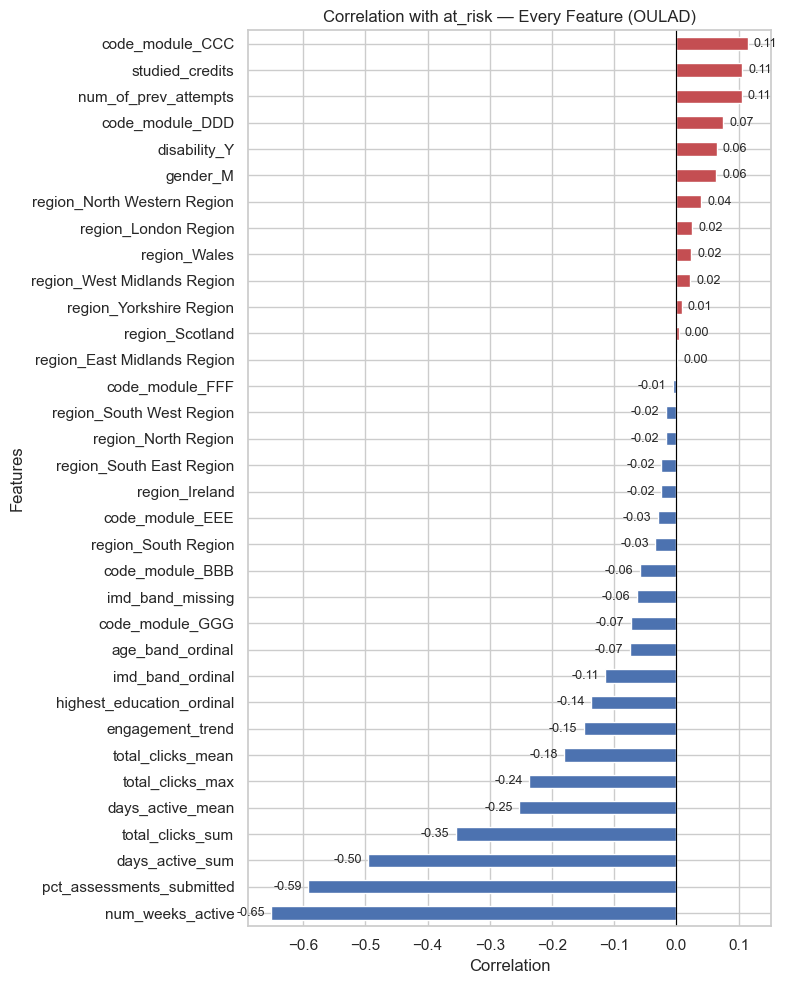

In [24]:
# 32. Feature Correlation with at_risk

# Calculate correlations with the target
target_corr = (
    df_features
    .corr(numeric_only=True)["at_risk"]
    .drop("at_risk")
)

# Sort from lowest to highest correlation
target_corr = target_corr.sort_values()


# Create bar colors
colors = [
    "#C44E52" if value > 0 else "#4C72B0"
    for value in target_corr
]


# Create plot
fig, ax = plt.subplots(figsize=(8, 10))

target_corr.plot(
    kind="barh",
    ax=ax,
    color=colors
)


# Reference line at zero
ax.axvline(
    0,
    color="black",
    linewidth=0.8
)


# Add correlation values to bars
for i, value in enumerate(target_corr):

    offset = 0.01 if value >= 0 else -0.01

    ax.text(
        value + offset,
        i,
        f"{value:.2f}",
        va="center",
        ha="left" if value >= 0 else "right",
        fontsize=9
    )


# Labels and title
ax.set_title(
    "Correlation with at_risk — Every Feature (OULAD)"
)

ax.set_xlabel("Correlation")
ax.set_ylabel("Features")


plt.tight_layout()
plt.show()

#### 2. Correlation heatmap

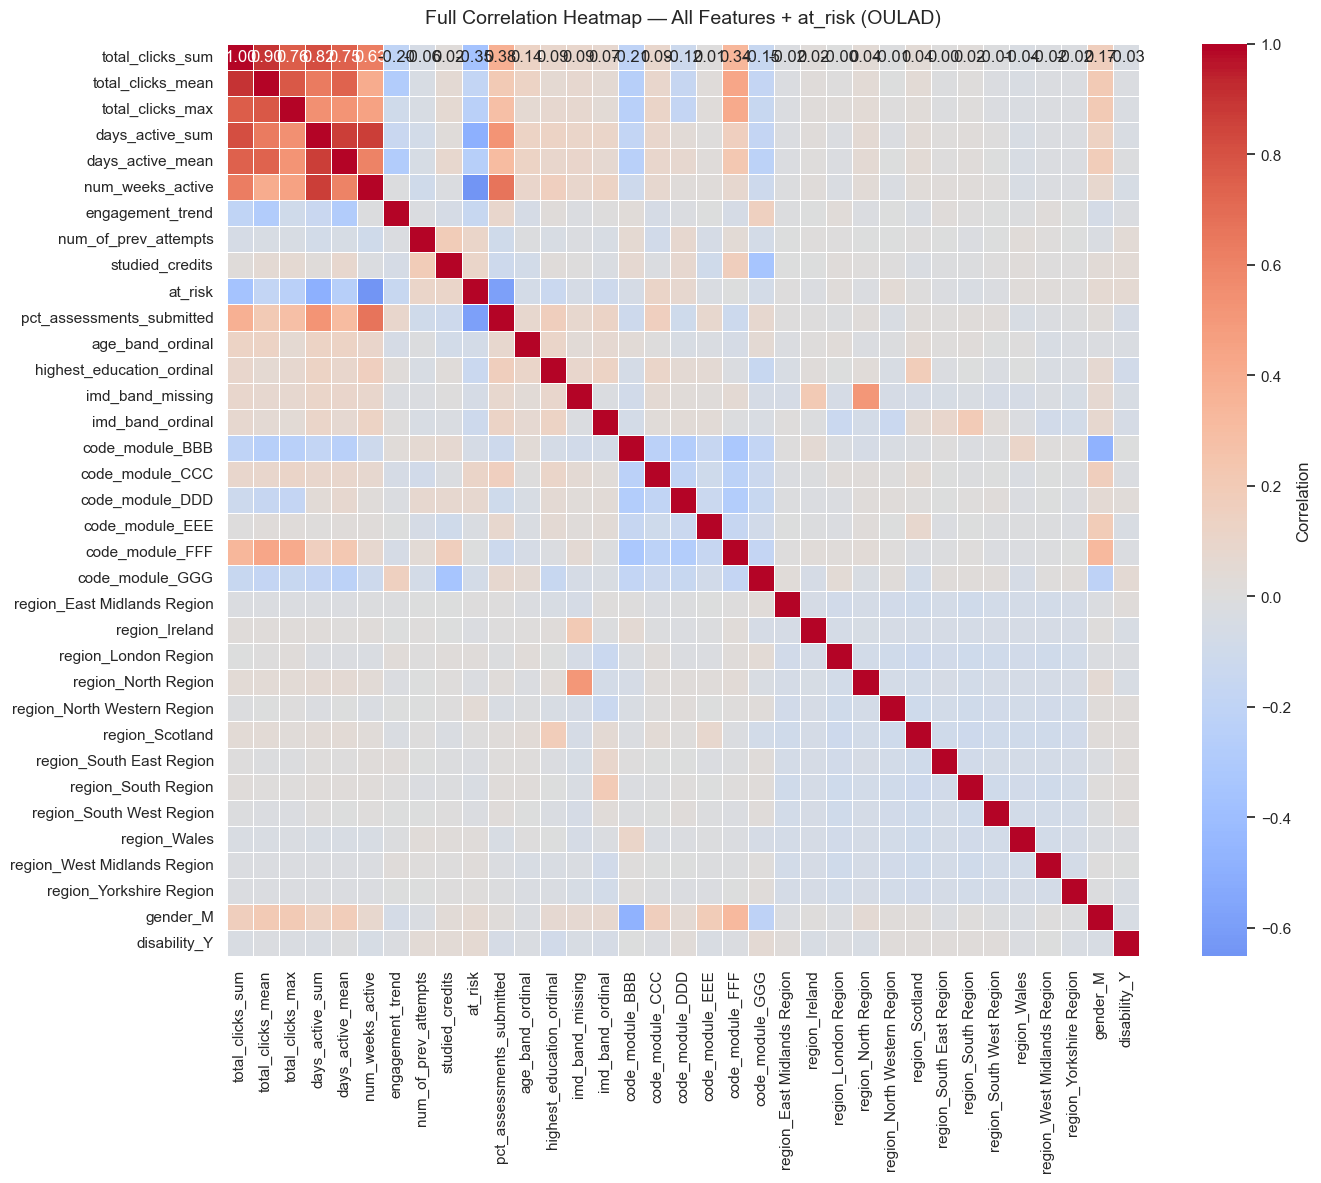

In [26]:
# 33. Full Correlation Heatmap — OULAD

# Calculate correlation matrix
full_corr = df_features.corr(numeric_only=True)


# Create heatmap
fig, ax = plt.subplots(figsize=(15, 12))

sns.heatmap(
    full_corr,
    cmap="coolwarm",
    center=0,
    annot=True,
    fmt=".2f",
    linewidths=0.5,
    square=True,
    ax=ax,
    cbar_kws={"label": "Correlation"}
)


# Title
ax.set_title(
    "Full Correlation Heatmap — All Features + at_risk (OULAD)",
    fontsize=14,
    pad=15
)

plt.tight_layout()
plt.show()

#### 3. Target leakage check plot

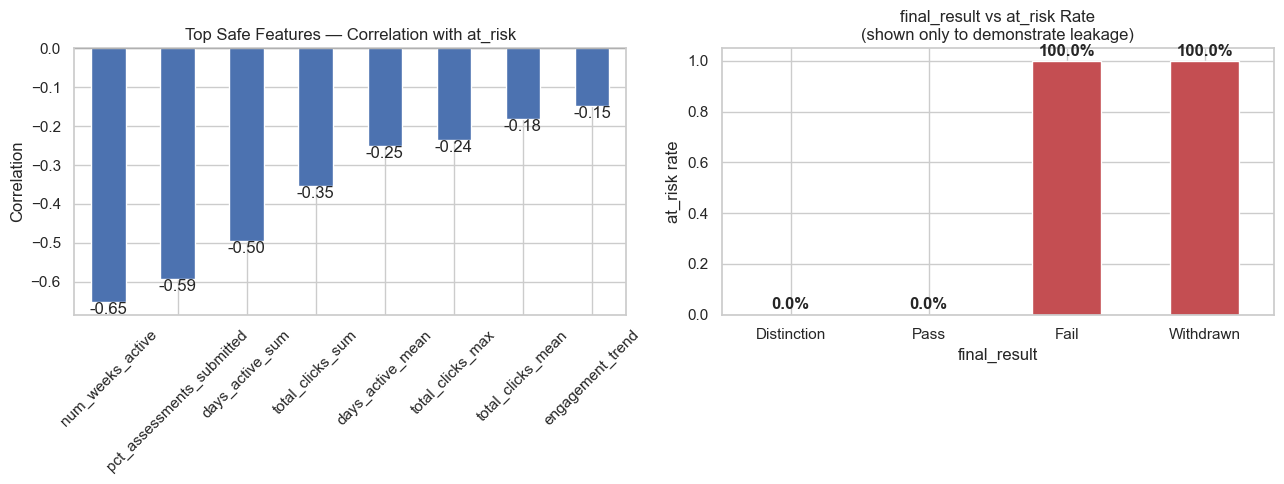

Is final_result in df_features? False
Confirmed: final_result is excluded from the saved feature matrix.


In [ ]:

# --------------------------------------------------
# 1. Check how final_result relates to at_risk
# --------------------------------------------------

final_result_risk = (
    merged
    .groupby("final_result")["at_risk"]
    .mean()
    .reindex([
        "Distinction",
        "Pass",
        "Fail",
        "Withdrawn"
    ])
)


# --------------------------------------------------
# 2. Get top correlated safe features
# --------------------------------------------------

top_features = (
    target_corr
    .reindex(
        target_corr.abs()
        .sort_values(ascending=False)
        .index
    )
    .head(8)
)


# --------------------------------------------------
# 3. Create comparison plots
# --------------------------------------------------

fig, axes = plt.subplots(
    1,
    2,
    figsize=(13, 5)
)


# ----- Top feature correlations -----

top_features.plot(
    kind="bar",
    ax=axes[0],
    color="#4C72B0"
)

axes[0].set_title(
    "Top Safe Features — Correlation with at_risk"
)

axes[0].set_ylabel("Correlation")
axes[0].axhline(
    0,
    color="black",
    linewidth=0.8
)

axes[0].tick_params(
    axis="x",
    rotation=45
)


# Add values to bars
for i, value in enumerate(top_features):

    axes[0].text(
        i,
        value,
        f"{value:.2f}",
        ha="center",
        va="bottom" if value >= 0 else "top"
    )


# ----- final_result leakage check -----

final_result_risk.plot(
    kind="bar",
    ax=axes[1],
    color="#C44E52"
)

axes[1].set_title(
    "final_result vs at_risk Rate\n"
    "(shown only to demonstrate leakage)"
)

axes[1].set_ylabel("at_risk rate")

axes[1].tick_params(
    axis="x",
    rotation=0
)


# Add percentages to bars
for i, value in enumerate(final_result_risk):

    axes[1].text(
        i,
        value + 0.02,
        f"{value:.1%}",
        ha="center",
        fontweight="bold"
    )


plt.tight_layout()
plt.show()


# --------------------------------------------------
# 4. Confirm final_result was excluded
# --------------------------------------------------

print(
    f"Is final_result in df_features? "
    f"{'final_result' in df_features.columns}"
)

assert "final_result" not in df_features.columns, (
    "LEAKAGE: final_result must not be in the feature matrix"
)

print(
    "Confirmed: final_result is excluded "
    "from the saved feature matrix."
)

**Reading this:** the right panel shows `final_result`'s relationship to
`at_risk` — 0% for Distinction/Pass, 100% for Fail/Withdrawn, by definition
(`at_risk` is a direct recoding of it). That perfect split is exactly why it
can't be a feature; the assert statement is the actual guardrail, the chart
just makes the reasoning visible.

#### 4. Boxplots — key predictors by risk

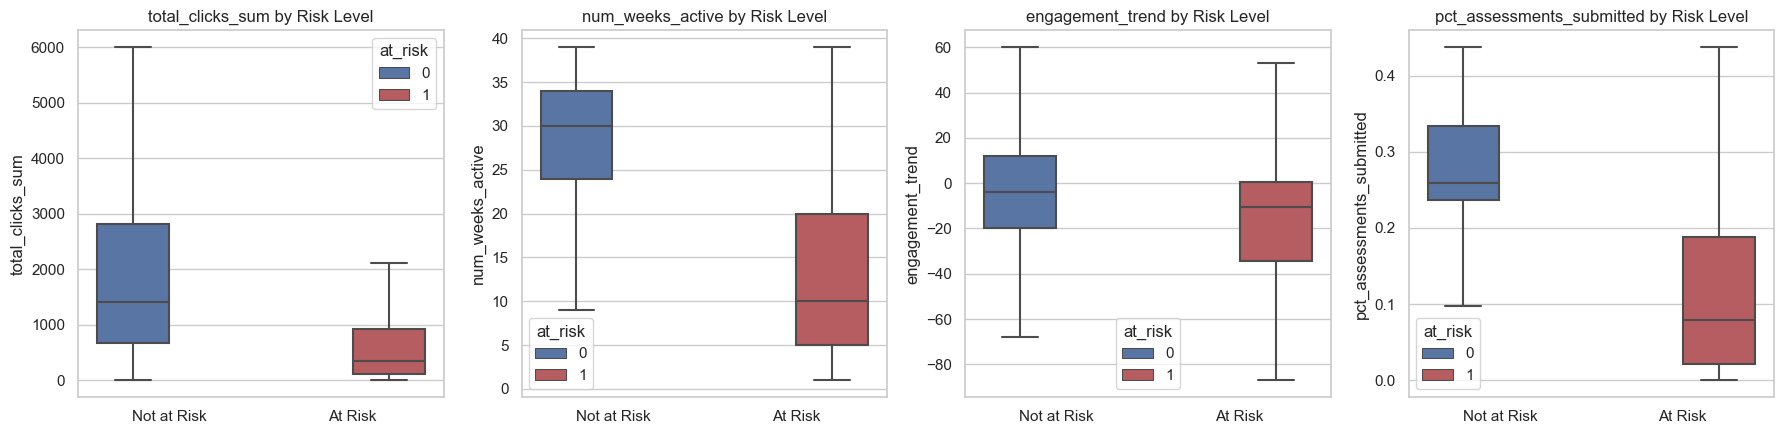

In [30]:
# 35. Engagement Features by Risk Level

# Features to compare
box_cols = [
    "total_clicks_sum",
    "num_weeks_active",
    "engagement_trend",
    "pct_assessments_submitted"
]

# Keep only available features
box_cols = [
    col for col in box_cols
    if col in df_features.columns
]


# Create subplots
fig, axes = plt.subplots(
    1,
    len(box_cols),
    figsize=(4.5 * len(box_cols), 4.5)
)


# Make axes iterable when only one plot exists
if len(box_cols) == 1:
    axes = [axes]


# Create boxplots
for ax, col in zip(axes, box_cols):

    sns.boxplot(
        data=df_features,
        x="at_risk",
        y=col,
        hue="at_risk",
        palette={
            0: "#4C72B0",
            1: "#C44E52"
        },
        showfliers=False,
        ax=ax
    )

    ax.set_xticks([0, 1])
    ax.set_xticklabels([
        "Not at Risk",
        "At Risk"
    ])

    ax.set_xlabel("")
    ax.set_ylabel(col)
    ax.set_title(
        f"{col} by Risk Level"
    )


plt.tight_layout()
plt.show()

**Reading this:** `engagement_trend` should skew more negative for `at_risk=1`
(declining engagement) than `at_risk=0` — if the boxes barely differ, the trend
feature isn't adding much beyond what `total_clicks_sum`/`num_weeks_active`
already capture, worth knowing before assuming it will help the model.
`pct_assessments_submitted` should show a clear gap, consistent with the
submission-funnel finding from the deep-dive EDA.

#### 5. Risk rate by category (new demographic features)

Encoded demographic features:
['code_module_BBB', 'code_module_CCC', 'code_module_DDD', 'code_module_EEE', 'code_module_FFF', 'code_module_GGG', 'region_East Midlands Region', 'region_Ireland', 'region_London Region', 'region_North Region', 'region_North Western Region', 'region_Scotland', 'region_South East Region', 'region_South Region', 'region_South West Region', 'region_Wales', 'region_West Midlands Region', 'region_Yorkshire Region', 'gender_M', 'disability_Y']


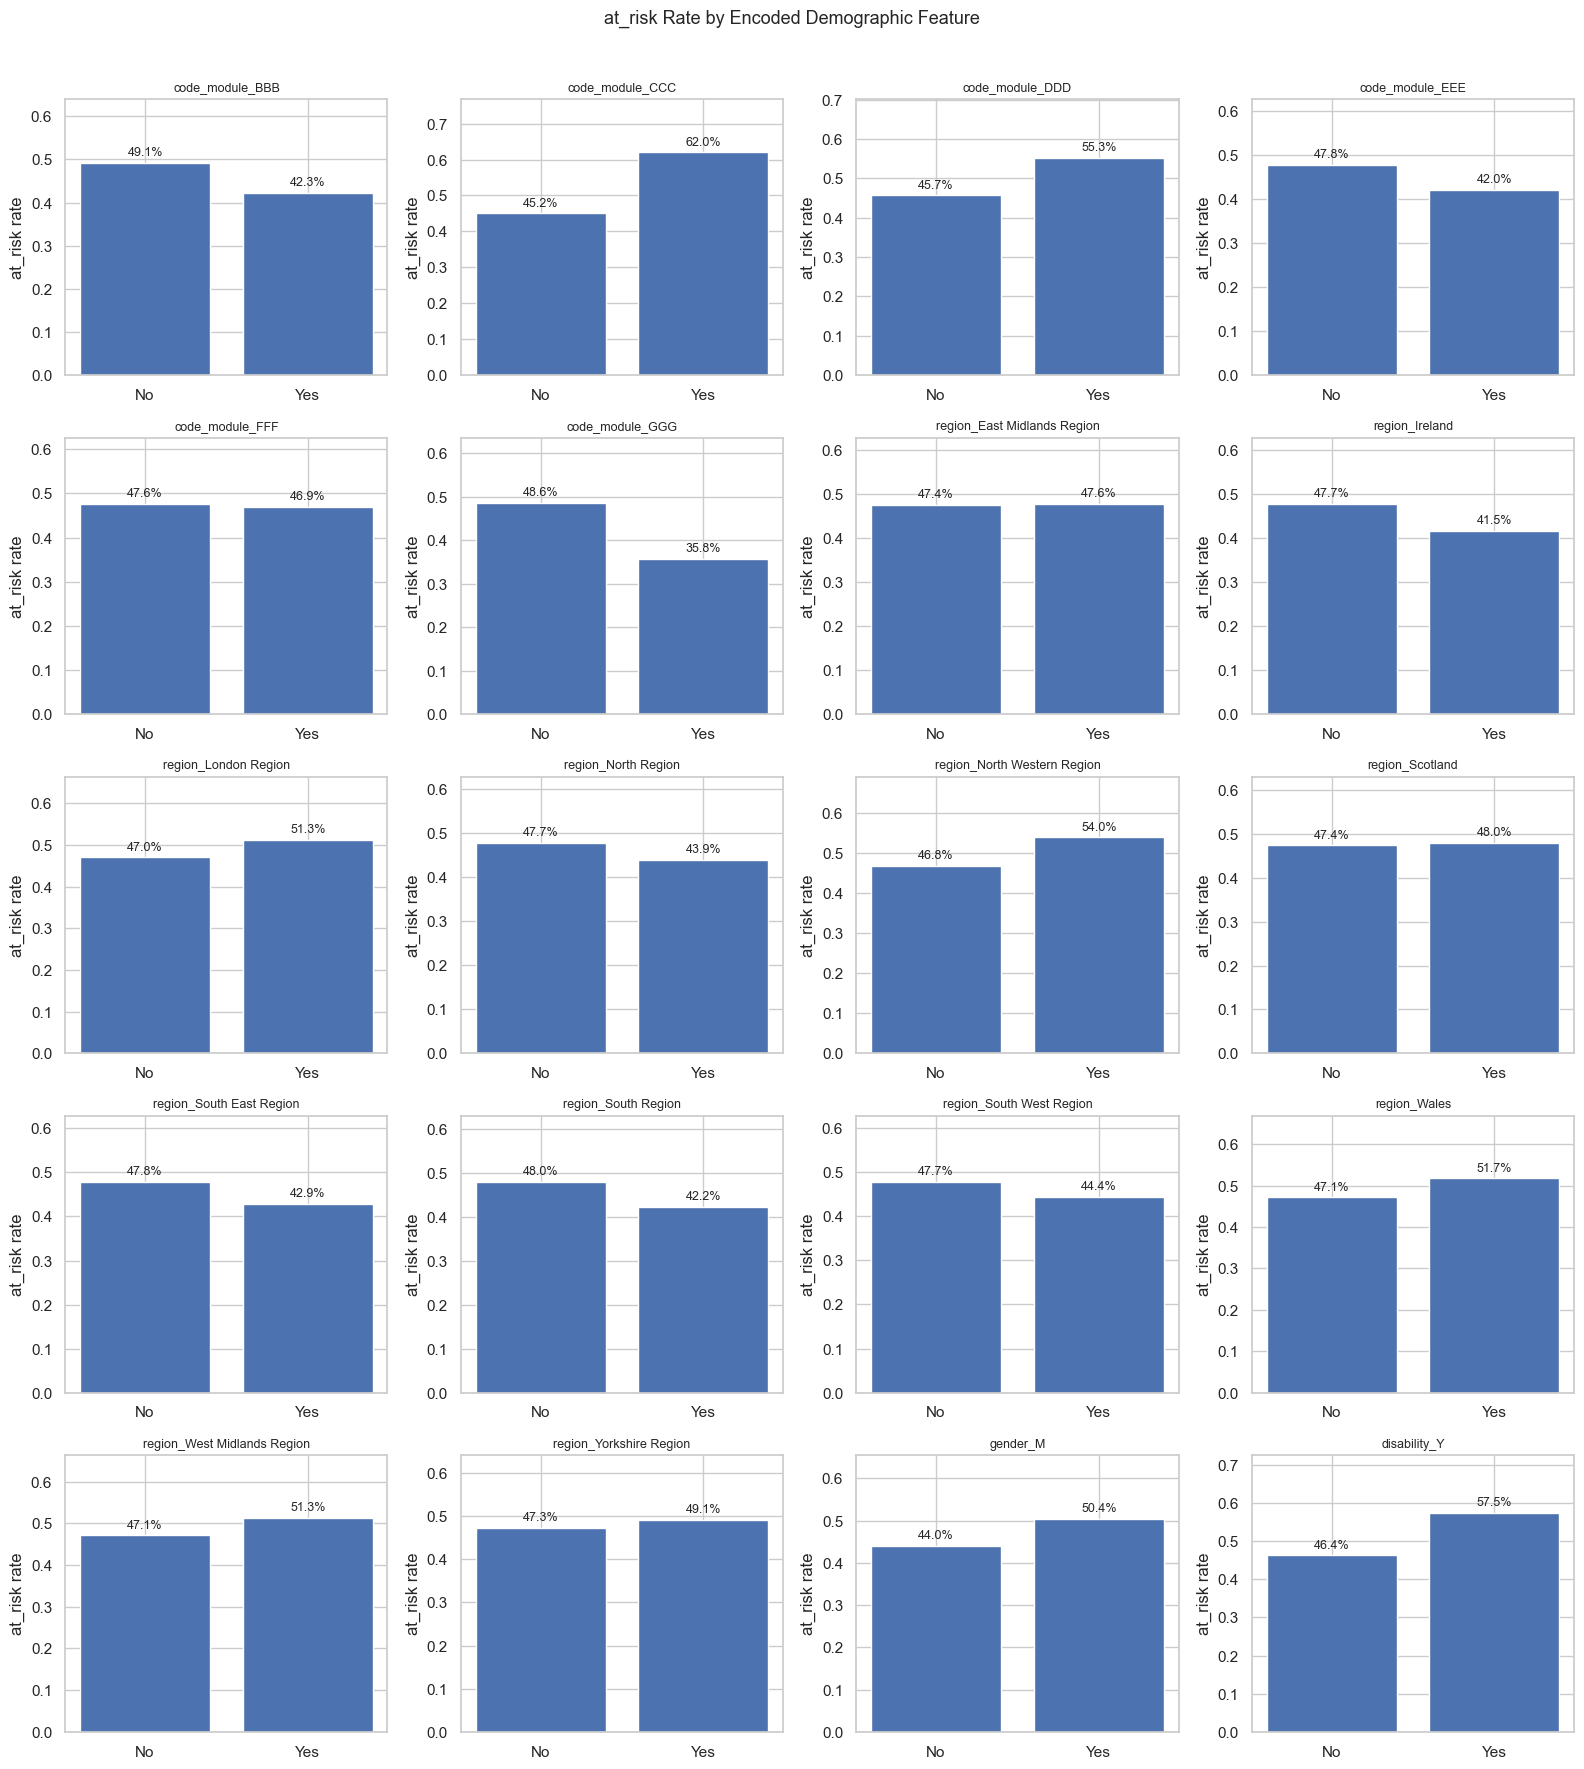

In [31]:
# 36. Risk Rate by Encoded Demographic Features

# Find one-hot encoded demographic columns
encoded_demo_cols = [
    col for col in df_features.columns
    if col.startswith((
        "region_",
        "gender_",
        "disability_",
        "code_module_"
    ))
]

print("Encoded demographic features:")
print(encoded_demo_cols)


# Number of plots per row
n_cols = 4
n_rows = (len(encoded_demo_cols) + n_cols - 1) // n_cols


# Create subplots
fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(4 * n_cols, 3.5 * n_rows)
)

axes = np.array(axes).flatten()


# Plot risk rate for each encoded feature
for ax, col in zip(axes, encoded_demo_cols):

    risk_rate = (
        df_features
        .groupby(col)["at_risk"]
        .mean()
    )

    # Convert True/False to readable labels
    if set(risk_rate.index).issubset({0, 1, False, True}):
        risk_rate.index = [
            "No" if value == 0 else "Yes"
            for value in risk_rate.index
        ]

    bars = ax.bar(
        risk_rate.index.astype(str),
        risk_rate.values,
        color="#4C72B0"
    )

    # Add values on bars
    for bar, value in zip(bars, risk_rate.values):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            value + 0.01,
            f"{value:.1%}",
            ha="center",
            va="bottom",
            fontsize=9
        )

    ax.set_title(col, fontsize=9)
    ax.set_ylabel("at_risk rate")
    ax.set_ylim(0, min(1.0, max(risk_rate.values) + 0.15))


# Hide unused subplot areas
for ax in axes[len(encoded_demo_cols):]:
    ax.axis("off")


fig.suptitle(
    "at_risk Rate by Encoded Demographic Feature",
    fontsize=13,
    y=1.01
)

plt.tight_layout()
plt.show()

#### 6. Target distribution

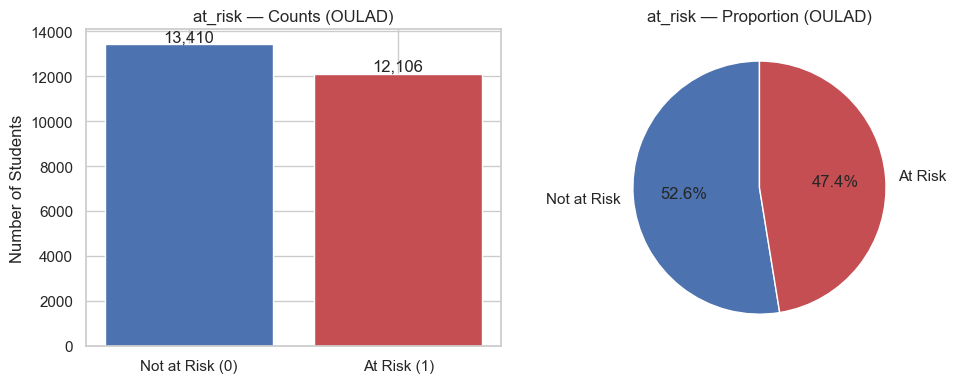

At-risk rate: 47.4% (12,106 of 25,516 students)


In [32]:
# 37. OULAD Class Balance — at_risk

# Calculate counts and percentages
counts = df_features["at_risk"].value_counts().sort_index()
rates = df_features["at_risk"].value_counts(normalize=True).sort_index()


# Create plots
fig, axes = plt.subplots(
    1, 2,
    figsize=(10, 4)
)


# --------------------------------------------------
# 1. Class counts
# --------------------------------------------------

bars = axes[0].bar(
    ["Not at Risk (0)", "At Risk (1)"],
    counts.values,
    color=["#4C72B0", "#C44E52"]
)

axes[0].set_title("at_risk — Counts (OULAD)")
axes[0].set_ylabel("Number of Students")


# Add count labels
for bar, value in zip(bars, counts.values):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        value,
        f"{value:,}",
        ha="center",
        va="bottom"
    )


# --------------------------------------------------
# 2. Class proportions
# --------------------------------------------------

axes[1].pie(
    rates.values,
    labels=["Not at Risk", "At Risk"],
    autopct="%1.1f%%",
    colors=["#4C72B0", "#C44E52"],
    startangle=90
)

axes[1].set_title("at_risk — Proportion (OULAD)")


# Layout
plt.tight_layout()
plt.show()


# --------------------------------------------------
# 3. Print summary
# --------------------------------------------------

total_students = counts.sum()
at_risk_count = counts.get(1, 0)
at_risk_rate = rates.get(1, 0)

print(
    f"At-risk rate: {at_risk_rate:.1%} "
    f"({at_risk_count:,} of {total_students:,} students)"
)

## 9. Summary — target, features, and what changed in this update

**Target:** unchanged — `at_risk` derived from `final_result`
(`Fail`/`Withdrawn` → 1).

**New features added, each tied to a specific deep-dive EDA finding:**
1. **`engagement_trend`** — second-half vs. first-half mean weekly clicks;
   responds to the cumulative-trajectory chart showing outcome groups diverge
   in *shape* over time, not just total volume.
2. **`pct_assessments_submitted`** — responds to the submission-funnel finding
   that non-submission is itself a risk signal, separate from low scores.
3. **`gender`, `region`, `highest_education`, `imd_band` (+ `imd_band_missing`),
   `age_band`** — responds to the correlation + RandomForest EDA check finding
   real demographic signal beyond the 2 columns (`num_of_prev_attempts`,
   `studied_credits`) the original version used.

**Encoding treatment matched to each column's actual structure** — nominal
one-hot for `code_module`/`region`, ordinal integer mapping for
`age_band`/`highest_education`/`imd_band` (preserves real ordering one-hot
would discard), binary one-hot for `gender`/`disability`.

**Same limitation as before, still not silently inherited:** the inner join
against `studentVle` still drops students with zero VLE activity (~9.4% in the
original run) — a candidate follow-up, not fixed here.

**Feature matrix saved** to `data/processed/oulad_feature_matrix.csv` — same
path as before, so `model_training_oulad.ipynb` picks up the richer matrix
automatically on its next run. Whether these additions actually **increase
accuracy** (not just correlation) gets tested for real in that notebook.